<a href="https://colab.research.google.com/github/Rohan-724/DSA0404/blob/main/EXP_11_FODS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pdfplumber

from google.colab import files

uploaded = files.upload()

pdf_file = next(iter(uploaded))

print("PDF uploaded successfully:", pdf_file)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 30.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 53.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 44.5 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


Saving 2,4,11Sales (1).pdf to 2,4,11Sales (1).pdf
PDF uploaded successfully: 2,4,11Sales (1).pdf


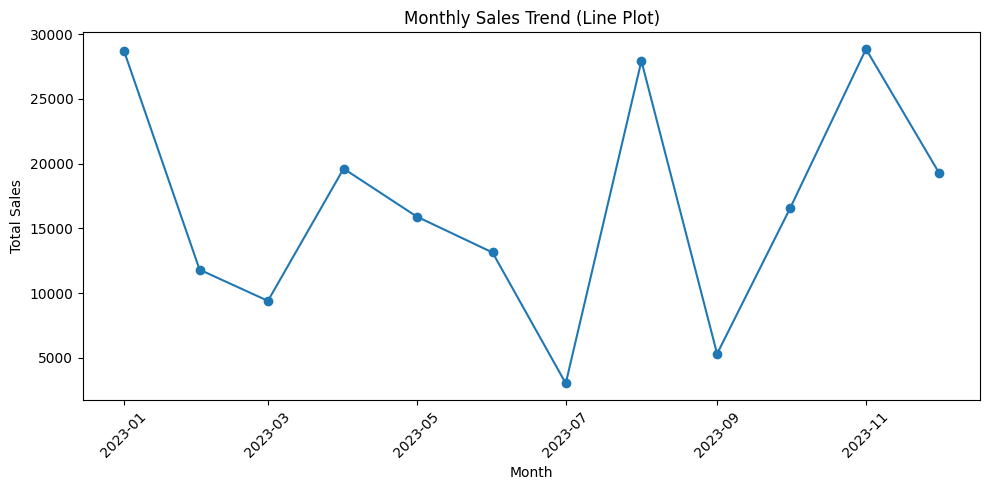

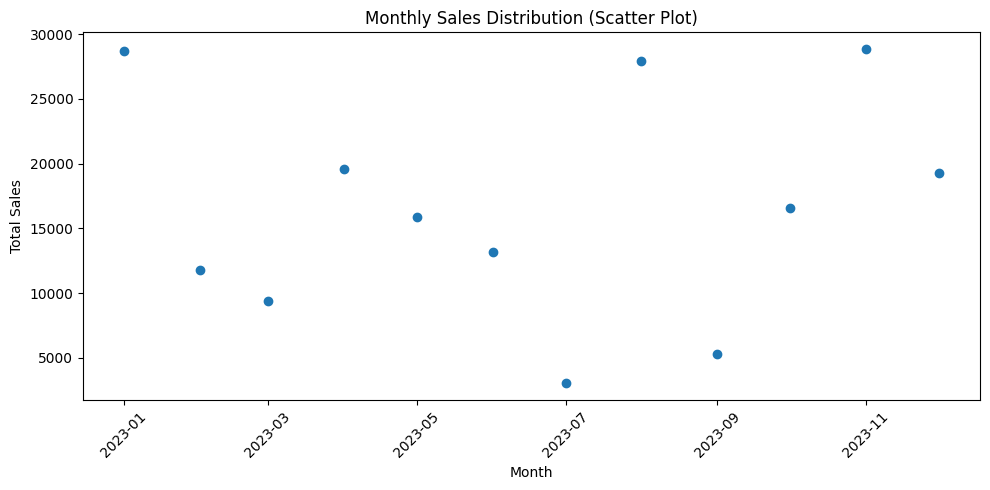

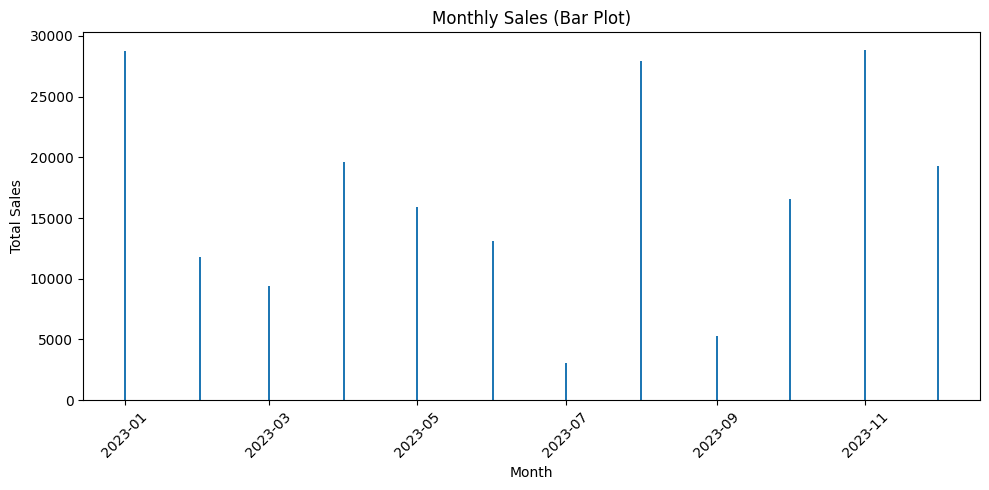

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber

all_data = []


with pdfplumber.open(pdf_file) as pdf:
    for page in pdf.pages:
        tables = page.extract_tables()

        for table in tables:
            if not table or len(table) < 2:
                continue

            headers = [
                str(col).strip().replace("\n", "_")
                if col else ""
                for col in table[0]
            ]

            required = [
                "Product_ID", "Month_sales", "Sales_Rep",
                "Region", "Total", "Quantity_Sold"
            ]

            if all(col in headers for col in required):
                df = pd.DataFrame(table[1:], columns=headers)
                all_data.append(df[required])

if not all_data:
    print("No matching sales tables found in the PDF.")

else:
    df = pd.concat(all_data, ignore_index=True)


    df["Total"] = pd.to_numeric(df["Total"], errors="coerce")


    df = df.dropna(subset=["Month_sales", "Total"])


    monthly_sales = df.groupby("Month_sales")["Total"].sum()


    monthly_sales.index = pd.to_datetime(
        monthly_sales.index, format="%B %Y"
    )

    monthly_sales = monthly_sales.sort_index()


    plt.figure(figsize=(10, 5))
    plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
    plt.title("Monthly Sales Trend (Line Plot)")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(10, 5))
    plt.scatter(monthly_sales.index, monthly_sales.values)
    plt.title("Monthly Sales Distribution (Scatter Plot)")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(10, 5))
    plt.bar(monthly_sales.index, monthly_sales.values)
    plt.title("Monthly Sales (Bar Plot)")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()